# Pet Shop Product Recommendations

> **Sample data disclaimer:** This notebook uses sample data, not the original business data. Recommendation examples and association metrics are specific to this sample and may differ when original data is used.

This notebook demonstrates purchase-history-based recommendations. Browsing behavior is not included in the available sample tables.
___

# Setup


In [1]:
# Install the interactive visualization library
!pip install -q  --upgrade plotly

     |████████████████████████████████| 25.3 MB 43.7 MB/s 


In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date, timedelta

In [3]:
from pathlib import Path
from src.data import load_raw_tables

data_dir = Path('../data/sample')
customers_df, products_df, sales_df = load_raw_tables(data_dir)

Mounted at /gdrive


# 1. Data Acquisition

Load the source tables and perform initial data cleaning.


In [ ]:
customers_df.head()

In [5]:
products_df.head()

,PRODUCT_ID,UNIT,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
0,0,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
1,1,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
2,2,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
3,3,UN,,,,
4,4,UN,CAES,FARMACIA,DORES E INFECCOES,ANTIBIOTICOS
...,...,...,...,...,...,...
38303,38303,UN,,,,
38304,38304,UN,,,,
38305,38305,UN,,,,
38306,38306,UN,,,,


In [6]:
sales_df.head()

,SALE_ID,SALE_DATE,CUSTOMER_ID,PRODUCT_ID,QUANTITY,SALE_CATEGORY,BRANCH
0,0,2021-02-10,45659,17631,1.0,E-COMMERCE,101
1,0,2021-02-10,45659,34575,1.0,E-COMMERCE,101
2,1,2021-02-12,70766,2240,1.0,E-COMMERCE,101
3,2,2021-02-12,42579,17707,1.0,E-COMMERCE,101
4,2,2021-02-12,42579,8952,1.0,E-COMMERCE,101
...,...,...,...,...,...,...,...
1859578,854530,2021-10-23,NaN,36642,10.0,Loja,113
1859579,854530,2021-10-23,NaN,7332,10.0,Loja,113
1859580,854530,2021-10-23,NaN,7333,10.0,Loja,113
1859581,854531,2021-10-23,106865,7528,1.0,Loja,113


# 2. Exploratory Data Analysis

Explore the main data volumes.


### 2.1 Products


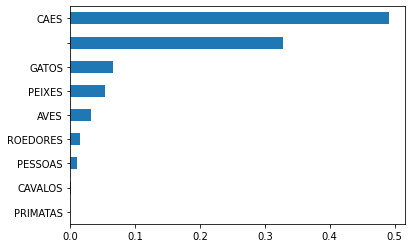

In [7]:
products_df['LEVEL_1'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

In [8]:
product_counts=products_df.groupby(['LEVEL_1', 'LEVEL_2', 'LEVEL_3'])['PRODUCT_ID'].count().reset_index()

In [9]:
import plotly.express as px
fig = px.sunburst(product_counts, path=['LEVEL_1', 'LEVEL_2', 'LEVEL_3'],values='PRODUCT_ID')
fig.show()

### 2.2 Sales


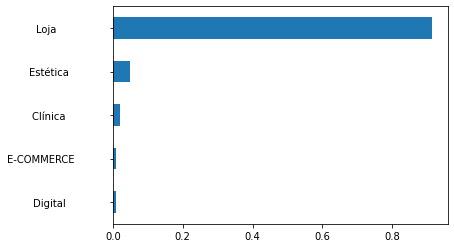

In [10]:
sales_df['SALE_CATEGORY'].value_counts(normalize=True).sort_values(ascending=True).plot(kind='barh')

In [11]:
sales_df['ORDER_KEY']=sales_df['BRANCH'].astype(str)+'_'+sales_df['SALE_ID'].astype(str).str.zfill(8)

In [12]:
orders = sales_df.groupby(['ORDER_KEY','BRANCH']).agg({'PRODUCT_ID':'nunique','QUANTITY':'sum'}).reset_index()
orders.head(10)

,ORDER_KEY,BRANCH,PRODUCT_ID,QUANTITY
0,101_00000000,101,2,2.0
1,101_00000001,101,1,1.0
2,101_00000002,101,4,6.0
3,101_00000003,101,1,1.0
4,101_00000004,101,1,1.0
5,101_00000005,101,2,2.0
6,101_00000006,101,2,2.0
7,101_00000007,101,2,3.0
8,101_00000008,101,2,2.0
9,101_00000009,101,1,1.0


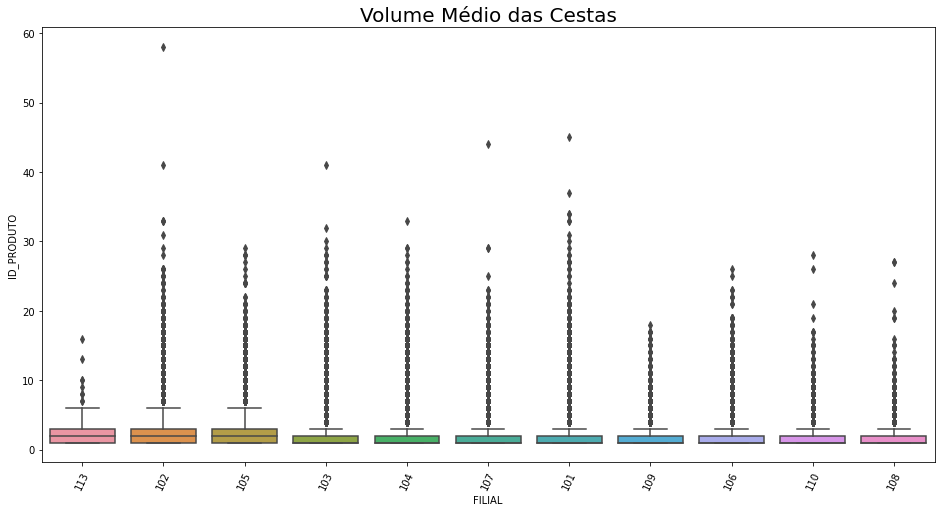

In [13]:
box_order = list(orders.groupby('BRANCH')['PRODUCT_ID'].mean().sort_values(ascending=False).index)

plt.figure(figsize=(16,8))
plt.xticks(rotation=65)
plt.title('Average Basket Size', fontsize=20)

sns.boxplot(data=orders, x='BRANCH', y='PRODUCT_ID', order=box_order)
plt.show()

# 3. Models


### 3.1 Collaborative Filtering


Collaborative filtering uses relationships between products and customer interests. It learns from purchase interactions to find products that may be relevant to customers with similar histories.


In [14]:
top_similar_items = 20 # Number of similar products to retrieve
days_window = 60       # Lookback window in days
recent_customer_days = 5        # Select customers active in the most recent days
min_purchase_count = 5    # Minimum purchase count for recommendation modeling
recommendation_count = 20            # Number of recommendations per customer

To keep memory usage manageable, this example uses recent data from branch 101 (e-commerce).


In [15]:
# Create a dataframe with sales, product, and customer information
latest_sale_date = sales_df['SALE_DATE'].max()
recent_sales = sales_df.loc[(sales_df['BRANCH']==101) & (sales_df['SALE_DATE']>=(latest_sale_date - timedelta(days=days_window)).strftime('%Y-%m-%d'))]

purchase_history = recent_sales[['SALE_DATE','PRODUCT_ID','CUSTOMER_ID']].copy()

purchase_history['PRODUCT_ID'] = purchase_history['PRODUCT_ID'].str.strip()
purchase_history['CUSTOMER_ID'] = purchase_history['CUSTOMER_ID'].str.strip()
purchase_history

,SALE_DATE,PRODUCT_ID,CUSTOMER_ID
5450,2021-08-27,3324,93165
5451,2021-08-27,3399,87587
5452,2021-08-27,7978,98487
5453,2021-08-27,11667,68647
5454,2021-08-27,3342,32871
...,...,...,...
462787,2021-10-25,7961,48998
462788,2021-10-25,32637,6592
462789,2021-10-25,5259,56513
462790,2021-10-25,34639,56513


In [16]:
# Filter frequent customers to reduce memory usage; the threshold is controlled by the parameter
frequent_customers = purchase_history.groupby(['CUSTOMER_ID'], as_index=False)['SALE_DATE'].count()
frequent_customers = frequent_customers[frequent_customers['SALE_DATE'] > min_purchase_count]
  
filtered_purchase_history = purchase_history.loc[purchase_history['CUSTOMER_ID'].isin(frequent_customers['CUSTOMER_ID'].to_list())].reset_index(drop=True)

The model uses up to 60 days of purchase history for this branch to recommend products to recent customers. Recent customers are included even if they do not meet the minimum purchase count used to build the similarity matrix.


In [17]:
# Select recent customers for recommendations
recent_purchases = purchase_history[purchase_history['SALE_DATE'] >= ((latest_sale_date - timedelta(days=recent_customer_days)).strftime(r'%Y-%m-%d'))].reset_index(drop=True)

# Concatenate the datasets and remove duplicates
filtered_purchase_history = pd.concat([filtered_purchase_history, recent_purchases]).drop_duplicates().reset_index(drop=True)

In [18]:
from scipy import sparse
from sklearn.metrics.pairwise import cosine_similarity
def calculate_similarity(item_data):
    """Calculate cosine similarity for each item 
    and return a DataFrame containing the item similarity matrix
    """
    sparse_item_data = sparse.csr_matrix(item_data)
    similarities = cosine_similarity(sparse_item_data.transpose())
    similarity_matrix = pd.DataFrame(data=similarities, index=item_data.columns, columns=item_data.columns)
    return similarity_matrix

def train_model(customer_product_data, normalize=True):
    """ Train the model
    """
    if normalize:
        # Normalize each customer vector so values range from 0 to 1
        magnitude = np.sqrt(np.square(customer_product_data).sum(axis=1)) # Square root of the sum of squared purchase counts
        customer_product_data = customer_product_data.div(magnitude, axis='index') # Divide purchase counts by their magnitude

    # Build the similarity matrix
    item_similarity_matrix = calculate_similarity(customer_product_data)

    return item_similarity_matrix

In [19]:
# Training matrix
# Aggregate purchases into a customer-by-product dataset
customer_product_interactions = filtered_purchase_history.groupby(['CUSTOMER_ID', 'PRODUCT_ID'], as_index=False)['SALE_DATE'].count()
customer_product_interactions.head()

,CUSTOMER_ID,PRODUCT_ID,SALE_DATE
0,1000,13533,1
1,1000,19083,1
2,1000,19576,1
3,1000,2060,1
4,1000,24945,1


In [20]:
# Convert to a sparse binary-style matrix
customer_product_matrix = customer_product_interactions.pivot_table(index='CUSTOMER_ID', columns='PRODUCT_ID', values='SALE_DATE', fill_value=0)
customer_product_matrix.head()

PRODUCT_ID,0,1,100,10025,10034,10050,10051,10052,10080,10094,10107,10169,10171,10174,10200,10238,10293,10331,10373,10392,10393,104,10580,10581,10583,10628,10653,10662,1082,10900,10901,110,11061,11082,11096,11103,11170,11172,11181,11194,...,9288,9292,9296,9297,9298,93,931,9318,933,9330,936,9370,9436,9516,9520,9536,955,956,9615,9616,9648,966,9668,9677,9678,9679,9689,969,9693,975,9755,9767,9768,9769,9770,9799,98,9822,9933,9945
CUSTOMER_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100030,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100037,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100049,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100080,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [21]:
# Train the model to generate product similarities
item_similarity_matrix = train_model(customer_product_matrix, normalize=True)
item_similarity_matrix.head()

PRODUCT_ID,0,1,100,10025,10034,10050,10051,10052,10080,10094,10107,10169,10171,10174,10200,10238,10293,10331,10373,10392,10393,104,10580,10581,10583,10628,10653,10662,1082,10900,10901,110,11061,11082,11096,11103,11170,11172,11181,11194,...,9288,9292,9296,9297,9298,93,931,9318,933,9330,936,9370,9436,9516,9520,9536,955,956,9615,9616,9648,966,9668,9677,9678,9679,9689,969,9693,975,9755,9767,9768,9769,9770,9799,98,9822,9933,9945
PRODUCT_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,1.000000,0.409776,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.525226,0.0,0.525226,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
1,0.409776,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.780189,0.0,0.780189,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
100,0.000000,0.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0
10025,0.000000,0.000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.050276,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.013696,0.0,0.0,0.0
10034,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0


In [22]:
# Build a matrix of the top 20 most similar products for each product
item_neighbors = pd.DataFrame(index=item_similarity_matrix.columns, columns=range(1, top_similar_items + 1))
for i in range(0, len(item_similarity_matrix.columns)):
    item_neighbors.iloc[i, :top_similar_items] = item_similarity_matrix.iloc[0:, i].sort_values(ascending=False)[:top_similar_items].index
item_neighbors.head()

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
PRODUCT_ID,,,,,,,,,,,,,,,,,,,,
0,0,6904,9005,11082,11103,16197,35255,19135,3430,9004,1,26094,31589,2,8827,33,17632,9271,12722,19342
1,1,9005,11103,11082,19135,8981,9004,6904,3316,0,36163,592,32281,3694,37865,19342,3693,12983,341,21582
100,100,7604,35921,12976,41,24486,24167,12984,3477,21578,21577,21573,21570,21569,21566,21565,9945,21562,21582,21561
10025,10025,21664,2131,13038,28427,28764,24644,28120,4684,7642,6901,2508,13078,33376,29496,12972,21655,28974,33496,35897
10034,10034,33640,33637,2541,37185,27640,3324,29580,28160,31670,4322,34727,8704,4811,5571,3471,3477,341,7763,3472


In [23]:
# Select customers with recent purchases
recent_customer_ids = recent_purchases.CUSTOMER_ID.unique()
recent_customer_ids=recent_customer_ids[recent_customer_ids.astype(str)!='nan']

recent_customer_ids

array(['105928', '81366', '54537', ..., '84245', '41318', '48998'],
      dtype=object)

In [24]:
# Generate recommendations
recommendations = pd.DataFrame(columns=['CUSTOMER_ID', 'PRODUCT_ID', 'SCORE'])
users_without_history = []

# Normalize the customer-product matrix 
magnitude = np.sqrt(np.square(customer_product_matrix).sum(axis=1))
item_data = customer_product_matrix.div(magnitude, axis='index')
item_data_transposed = item_data.T

for user in recent_customer_ids:
    # Lista de items comprados
    
    purchased_products = item_data_transposed[user]
    purchased_products = purchased_products[purchased_products > 0].index.values

    # Build the neighborhood of products similar to those purchased by the customer
    similar_products_by_purchase = item_neighbors.loc[purchased_products]
    neighbor_table = similar_products_by_purchase.values.tolist()
    # Convert to a list and remove duplicates
    candidate_products = list(set([item for sublist in neighbor_table for item in sublist]))
    candidate_similarity_matrix = item_similarity_matrix[candidate_products].loc[candidate_products]

    # Get similar products for the customer
    customer_product_vector = item_data.loc[user].loc[candidate_products]

    # Calculate a recommendation recommendation_scores for each product
    recommendation_scores = candidate_similarity_matrix.dot(customer_product_vector).div(candidate_similarity_matrix.sum(axis=1))

    # Return the top recommendations as a DataFrame
    customer_recommendations = pd.DataFrame(recommendation_scores.nlargest(recommendation_count)).reset_index().rename(columns={0: 'SCORE'})
    customer_recommendations.loc[:, 'CUSTOMER_ID'] = user

    recommendations = pd.concat([recommendations, customer_recommendations])


recommendations.head(50)

,CUSTOMER_ID,PRODUCT_ID,SCORE
0,105928,3968,0.241800
1,105928,31822,0.175428
2,105928,16758,0.157227
3,105928,17736,0.135502
4,105928,16191,0.134321
5,105928,8809,0.133815
6,105928,430,0.101324
7,105928,8824,0.098502
8,105928,32931,0.079616
9,105928,3281,0.075436


In [25]:
recommendations['CUSTOMER_ID']=recommendations['CUSTOMER_ID'].astype(int)
recommendations['PRODUCT_ID']=recommendations['PRODUCT_ID'].astype(int)
recommendations=recommendations.merge(customers_df,how='left')
recommendations=recommendations.merge(products_df,how='left')
recommendations.sort_values(['CUSTOMER_ID','SCORE'],ascending=False)#[['CUSTOMER_ID', 'PRODUCT_ID', 'SCORE', 'UNIT', 'LEVEL_1', 'LEVEL_2', 'LEVEL_3','LEVEL_4']]

,CUSTOMER_ID,PRODUCT_ID,SCORE,SEXO,BIRTH_DATE,FIRST_PURCHASE_DATE,UNIT,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
24780,106052,17712,0.160399,NaN,NaT,NaT,UN,CAES,FARMACIA,VITAMINAS E SUPLEMENTOS,VITAMINAS E SUPLEMENTOS
24781,106052,8568,0.138612,NaN,NaT,NaT,UN,CAES,FARMACIA,VITAMINAS E SUPLEMENTOS,VITAMINAS E SUPLEMENTOS
24782,106052,1236,0.134792,NaN,NaT,NaT,UN,CAES,ALIMENTOS,RACOES,RACAO UMIDA (SACHES E LATAS)
24783,106052,27288,0.123585,NaN,NaT,NaT,UN,CAES,ALIMENTOS,RACOES,RACAO UMIDA (SACHES E LATAS)
24784,106052,3315,0.122178,NaN,NaT,NaT,UN,CAES,ALIMENTOS,RACOES,RACAO SECA
...,...,...,...,...,...,...,...,...,...,...,...
22555,218,23505,0.065132,,1900-01-01,2017-04-24,UN,CAES,ACESSORIOS,ROUPINHAS E ACESSORIOS,FANTASIAS
22556,218,3881,0.062635,,1900-01-01,2017-04-24,UN,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
22557,218,35256,0.056299,,1900-01-01,2017-04-24,UN,CAES,ALIMENTOS,RACOES,RACAO UMIDA (SACHES E LATAS)
22558,218,33578,0.055581,,1900-01-01,2017-04-24,UN,CAES,ACESSORIOS,CAMINHAS E CASINHAS,CAMINHAS


In [29]:
# Example recommendations for a customer
recommendations[['CUSTOMER_ID','PRODUCT_ID','SCORE','LEVEL_1', 'LEVEL_2', 'LEVEL_3','LEVEL_4']].head(19)

,CUSTOMER_ID,PRODUCT_ID,SCORE,LEVEL_1,LEVEL_2,LEVEL_3,LEVEL_4
0,105928,3968,0.241800,CAES,FARMACIA,PELE E PELAGEM,TRATAMENTO PARA PELE
1,105928,31822,0.175428,CAES,HIGIENE E BELEZA,HIGIENE E LIMPEZA,SANITARIOS
2,105928,16758,0.157227,GATOS,FARMACIA,ACESSORIOS MEDICOS,ROUPA POS-CIRURGICA
3,105928,17736,0.135502,CAES,FARMACIA,DORES E INFECCOES,ANTI-INFLAMATORIOS
4,105928,16191,0.134321,CAES,ALIMENTOS,PETISCOS E OSSINHOS,BISCOITOS - BIFINHOS - SNACKS
5,105928,8809,0.133815,CAES,FARMACIA,PELE E PELAGEM,BANHO TERAPEUTICO
6,105928,430,0.101324,CAES,FARMACIA,PELE E PELAGEM,TRATAMENTO PARA PELE
7,105928,8824,0.098502,CAES,FARMACIA,DORES E INFECCOES,ANTIBIOTICOS
8,105928,32931,0.079616,CAES,ALIMENTOS,RACOES,RACAO MEDICAMENTOSA
9,105928,3281,0.075436,CAES,ALIMENTOS,RACOES,RACAO SECA


The resulting list contains recommendations for recent customers based on their purchase histories. It could support a CRM campaign or an online storefront. These examples are generated from sample data and have not been validated as production recommendations.


### 3.2 Basket Analysis


In [30]:
!pip install mlxtend --quiet
!pip install graphviz --quiet

# Association rules
from mlxtend.frequent_patterns import apriori, association_rules

import networkx as nx
from graphviz import Digraph
from graphviz import Source

This section explores relationships between products purchased together.

First, frequent itemsets are identified: groups of products that occur together in transactions. The key measures used to assess association rules are summarized below.

---
**Support**: The frequency with which an itemset appears in the dataset.

Association rules can be derived from frequent itemsets and assessed using measures such as confidence and lift.

---
**Confidence**

Of all transactions containing **A**, how many also contain **B**?

$Confidence(A \Rightarrow B) = \frac{Support(A, B)}{Support(A)}$

---
**Lift**

How much more often does **B** occur with **A** than expected from the support of **B** alone?

$Lift(A \Rightarrow B) = \frac{Confidence(A, B)}{Support(B)}$

- Lift = 1: no association beyond the baseline frequency.
- Lift > 1: positive association.
- Lift < 1: negative association.


As with collaborative filtering, this example uses a smaller dataset to manage memory usage. It uses branch 101 (e-commerce).


In [31]:
days_window = 60 #ultimos 60 dias
latest_sale_date = sales_df['SALE_DATE'].max()
recent_sales = sales_df.loc[(sales_df['BRANCH']==101) & (sales_df['SALE_DATE']>=(latest_sale_date - timedelta(days=days_window)).strftime('%Y-%m-%d'))]

purchase_history = recent_sales[['SALE_DATE','PRODUCT_ID','CUSTOMER_ID']].copy()
purchase_history

,SALE_DATE,PRODUCT_ID,CUSTOMER_ID
5450,2021-08-27,3324,93165
5451,2021-08-27,3399,87587
5452,2021-08-27,7978,98487
5453,2021-08-27,11667,68647
5454,2021-08-27,3342,32871
...,...,...,...
462787,2021-10-25,7961,48998
462788,2021-10-25,32637,6592
462789,2021-10-25,5259,56513
462790,2021-10-25,34639,56513


In [32]:
basket_matrix = purchase_history.groupby(['CUSTOMER_ID','PRODUCT_ID'])['SALE_DATE'].nunique().unstack().reset_index().fillna(0).set_index('CUSTOMER_ID')
basket_matrix.head(10)

PRODUCT_ID,13533,19083,19576,2060,24945,26861,27288,299,33606,35917,35921,3654,38308,42,4311,12985,12965,13128,12984,4003,16856,25062,3933,7763,3432,13017,36639,13378,17850,27291,29089,29141,3990,4001,4857,5105,15144,15557,17662,23944,...,431,2289,2298,2341,8060,14851,19422,22436,14280,17807,4686,30778,23164,12549,29034,29046,38313,21140,13344,6026,27999,6644,747,23690,5079,28954,11872,1254,1321,15941,15953,22315,24516,24534,26831,33284,11388,16750,12262,5838
CUSTOMER_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100005,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100022,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100027,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100030,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
100037,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [33]:
# Convert positive values to 1 and values less than 1 to 0
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1

binary_basket_matrix = basket_matrix.applymap(encode_units)
binary_basket_matrix

PRODUCT_ID,13533,19083,19576,2060,24945,26861,27288,299,33606,35917,35921,3654,38308,42,4311,12985,12965,13128,12984,4003,16856,25062,3933,7763,3432,13017,36639,13378,17850,27291,29089,29141,3990,4001,4857,5105,15144,15557,17662,23944,...,431,2289,2298,2341,8060,14851,19422,22436,14280,17807,4686,30778,23164,12549,29034,29046,38313,21140,13344,6026,27999,6644,747,23690,5079,28954,11872,1254,1321,15941,15953,22315,24516,24534,26831,33284,11388,16750,12262,5838
CUSTOMER_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1000,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100005,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100007,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
100018,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99961,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
99965,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
99980,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [34]:
# Association rules
from mlxtend.frequent_patterns import apriori, association_rules

The minimum support is set to 0.2% and the minimum confidence to 10%. These thresholds are exploratory choices for this sample and should be reassessed with the intended business data.


In [35]:
frequent_itemsets = apriori(binary_basket_matrix, min_support=0.001, use_colnames=True)
frequent_itemsets.sort_values('support',ascending=False)

,support,itemsets
26,0.140370,(38309)
6,0.122824,(38308)
220,0.042001,(38311)
786,0.027079,"(38309, 38308)"
37,0.025145,(3476)
...,...,...
873,0.001105,"(38309, 3969)"
672,0.001105,(8546)
396,0.001105,(27787)
671,0.001105,(4929)


For example, this sample shows support values of about 14% for product 38309 and 12% for product 38308. These values are sample-specific and may change with different data.


In [36]:
association_rules_df = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)
association_rules_df.sort_values(['lift','confidence'],ascending=False).head(20)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
186,(3696),(3695),0.002072,0.001934,0.001105,0.533333,275.733333,0.001101,2.138712
187,(3695),(3696),0.001934,0.002072,0.001105,0.571429,275.733333,0.001101,2.328498
140,(7332),(36641),0.001934,0.002349,0.001105,0.571429,243.294118,0.001101,2.327853
139,(36641),(7332),0.002349,0.001934,0.001105,0.470588,243.294118,0.001101,1.885235
274,"(16856, 16855)",(16854),0.001243,0.004421,0.001243,1.000000,226.187500,0.001238,inf
277,(16854),"(16856, 16855)",0.004421,0.001243,0.001243,0.281250,226.187500,0.001238,1.389574
215,(22979),(22978),0.002072,0.003454,0.001520,0.733333,212.314667,0.001513,3.737048
216,(22978),(22979),0.003454,0.002072,0.001520,0.440000,212.314667,0.001513,1.782014
314,"(170, 38309)",(13327),0.001520,0.004145,0.001243,0.818182,197.400000,0.001237,5.477204
318,(13327),"(170, 38309)",0.004145,0.001520,0.001243,0.300000,197.400000,0.001237,1.426400


In [37]:
from matplotlib import cm, colors
def normalize_value(x, min_val, max_val):
  if min_val == max_val:
    return x
  else:
    return (x - min_val)/(max_val - min_val)
    
def plot_association_graph(rules, image_size, color_schema, n_top, order_by, rule_color='lift', rule_width='support'):
  cmap = cm.get_cmap(color_schema, 100)

  sns.palplot(sns.color_palette(color_schema, n_colors=10), size=0.5)

  G = Digraph(strict=True, format='png')

  G.attr(size=image_size, splines='line')

  rules = rules.sort_values(by=order_by, ascending=False).head(n_top)

  max_color = max(rules[rule_color])
  min_color = min(rules[rule_color])

  max_width = max(rules[rule_width])
  min_width = min(rules[rule_width])

  rules['antecedents']= rules['antecedents'].apply(list)
  rules['consequents'] = rules['consequents'].apply(list)

  for index, row in rules.iterrows():

    antecedents = ','.join(row.antecedents)
    consequents = ','.join(row.consequents)

    node = antecedents + '->' + consequents

    color_val = normalize_value(row[rule_color], min_color, max_color)
    width_val = normalize_value(row[rule_width], min_width, max_width) + 0.2
    
    G.node(node, "", style='filled', color=cm.colors.to_hex(cmap(color_val)), shape='circle', width=str(width_val))
    for item in row.antecedents:
      G.node(item, item, shape='plaintext')
      G.edge(item, node, color = 'grey')

    for item in row.consequents:
      G.node(item, item, shape='plaintext')     
      G.edge(node, item, color = 'grey')

  return G

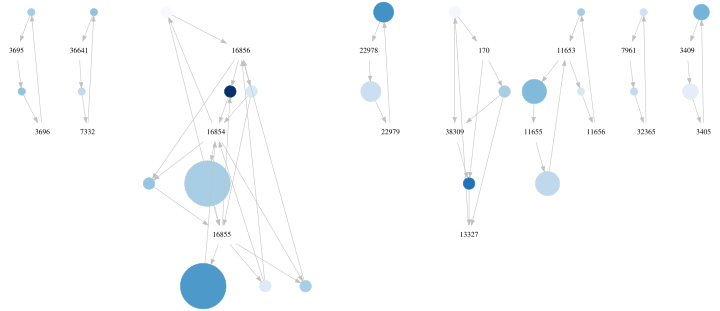

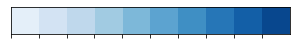

In [38]:
plot_association_graph(association_rules_df, '10', 'Blues', 25, order_by='lift', rule_color='confidence', rule_width='support')

In [46]:
association_rules_df[association_rules_df.antecedents==frozenset({'16855'})].head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage,conviction
41,(16855),(16856),0.003316,0.003178,0.001243,0.375000,118.010870,0.001233,1.594916
167,(16855),(16854),0.003316,0.004421,0.002349,0.708333,160.216146,0.002334,3.413413
278,(16855),"(16856, 16854)",0.003316,0.002211,0.001243,0.375000,169.640625,0.001236,1.596463


Frequent itemsets and association rules have been generated with Apriori. The rules can help identify products that co-occur in this sample, but they do not establish that one purchase causes another. Product IDs in the output should be mapped to readable product names before business use. Results may differ when the original business data is used.
